# 01 - Two sequential scans, reconstructed separately and subtracted

The naive baseline: scan once with the light off, scan again with the light on,
reconstruct each independently, subtract the two phase images.

## Why this notebook builds its own data

The rest of block 0 consumes the **interlaced** cube from notebook 00, where light-on and
light-off alternate position by position inside one scan. That is not what this method is.
Subtract-and-reconstruct is a *sequential* experiment - two complete scans, one after the
other - and the two scans land on grids that are **not registered to each other**. Each
reconstruction fixes its own object origin, its own global phase gauge and its own probe,
and the subtraction inherits every one of those mismatches. Feeding it a single interlaced
cube and de-interlacing it internally hides exactly the problem the method has, because
the two halves of an interlaced scan share a grid by construction.

So the two scans are generated here, in memory, and are **not written to disk**.

## Dose

The comparison is only fair at **equal total dose**. Notebook 00's interlaced cube puts
$D$ e/Å$^2$ on the specimen in one pass; two sequential scans therefore get $D/2$ each,
and the electron budget matches exactly:

| scheme | positions | step | dose per scan | e/position at $D = 10^6$ | total e |
|---|---|---|---|---|---|
| 00, interlaced | $182^2$ | 0.1641 Å | $D$ | 26,929 | $8.92\times10^8$ |
| **(1) same step** | $182^2$ $\times$ 2 scans | 0.1641 Å | $D/2$ | 13,464 | $8.92\times10^8$ |
| **(2) double step** | $91^2$ $\times$ 2 scans | 0.3282 Å | $D/2$ | 53,857 | $8.92\times10^8$ |

Configuration (2) is the honest comparison against the other methods, because
de-interlacing notebook 00's cube leaves each channel on exactly that $0.3282\ \mathrm{\AA}$
grid. Configuration (1) spends the same electrons on twice as many positions, so each
diffraction pattern is noisier but there are more of them.

## What this method is, in code

`method_wrappers.reconstruct_and_subtract` now takes the **two datacubes**, not one
interlaced cube. Internally it calls `ptychography` - a plain single-scan reconstruction -
once per scan and differences the two phases, returning the usual
`phase_off / phase_on / delta_phi / ptycho_off / ptycho_on`.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import abtem
from abtem.core.energy import energy2sigma
from abtem.potentials.iam import PotentialArray
from abtem.scan import CustomScan

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers
from quantem.core import config

config.set_device(0)

try:
    import cupy
    abtem.config.set({"device": "gpu"})
    ABTEM_DEVICE = "gpu"
except Exception:
    abtem.config.set({"device": "cpu"})
    ABTEM_DEVICE = "cpu"


def to_numpy(array):
    return array.get() if hasattr(array, "get") else np.asarray(array)


with open(DATA_DIR / "ideal_geometry.json") as handle:
    META = json.load(handle)
truth = np.load(DATA_DIR / "ideal_truth.npz")
phase_base = truth["phase_base"].astype(np.float64)
phase_excited = truth["phase_excited"].astype(np.float64)
delta_phi_true = truth["delta_phi_true"]

# the optics, straight out of 00's metadata - nothing restated by hand
ACC_VOLTAGE_EV       = META["beam"]["accelerating_voltage_eV"]
PROBE_SEMIANGLE_MRAD = META["beam"]["convergence_semiangle_mrad"]
PROBE_DEFOCUS_ANG    = META["beam"]["defocus_C10_ang"]
CELL_EXTENT_ANG      = META["cell"]["extent_ang"]
N_OBJECT_PX          = META["cell"]["n_pixels"]
OBJECT_DX_ANG        = META["cell"]["dx_ang"]
DETECTOR_BIN         = META["detector"]["bin"]
n_detector_binned    = META["detector"]["n_pixels_binned"]
n_detector_native    = META["detector"]["n_pixels_native"]
crop_half_angle_mrad = META["detector"]["collection_half_angle_mrad"]
binned_pitch_mrad    = META["detector"]["binned_pitch_mrad"]
BASE_STEP_ANG        = META["scan"]["step_ang"]
SCAN_EXTENT_ANG      = META["scan"]["extent_ang"]
SLICE_THICKNESS_ANG  = META["simulation"]["slice_thickness_ang"]
blob_centre          = np.array(META["object"]["blob_centre_ang"])
SCAN_ORIGIN_OFFSET_ANG = (N_OBJECT_PX // 2) * OBJECT_DX_ANG

print(f"optics from ideal_geometry.json: {ACC_VOLTAGE_EV/1e3:.0f} kV, "
      f"{PROBE_SEMIANGLE_MRAD} mrad, C10 = {PROBE_DEFOCUS_ANG} A")
print(f"object {N_OBJECT_PX}^2 at {OBJECT_DX_ANG:.6f} A/px; truth peak "
      f"{np.abs(delta_phi_true).max():.5f} rad")
print(f"abTEM device: {ABTEM_DEVICE}")

cuda:0
optics from ideal_geometry.json: 60 kV, 30.0 mrad, C10 = 100.0 A
object 900^2 at 0.098921 A/px; truth peak 0.02106 rad
abTEM device: gpu


In [2]:
DOSE_KEYS = ["inf", "1e6", "1e5"]
BASE_DOSE = {"inf": None, "1e6": 1e6, "1e5": 1e5}   # the TOTAL dose, as in 00

# two sequential scans share the total dose, so each gets half of it
DOSE_SPLIT = 0.5

SCAN_CONFIGS = {
    "step1x": dict(step_ang=BASE_STEP_ANG,     label="same step as 00"),
    "step2x": dict(step_ang=2 * BASE_STEP_ANG, label="double step (= the de-interlaced grid)"),
}

# Calibrated in this session: obj_lr swept over {1e-3, 1e-2, 1e-1, 5e-1} for 40 iterations,
# 1e-3 reached the lowest final loss and was within 2% of it by iteration 4.
NUM_ITERS = 60
OBJ_LR = 1e-3
PROBE_LR = 1e-4
TV_WEIGHT = 0.0        # the baseline is deliberately unregularised
BATCH_SIZE = 128

# Block 0 is the ideal case, so the two scans are commanded onto the SAME nominal grid and
# this offset is zero. The non-registration here is whatever the two independent
# reconstructions produce on their own - different origin, different gauge, different
# probe. Physical drift between the two scans belongs to block 1; notebook 11 turns this on.
INTER_SCAN_OFFSET_ANG = (0.0, 0.0)

# No fixed seed: the two scans get independent noise draws, and so does every run.

for tag, cfg in SCAN_CONFIGS.items():
    n = int(np.floor(SCAN_EXTENT_ANG / cfg["step_ang"]))
    cfg["n_scan"] = n
    print(f"{tag:7s} {cfg['label']:42s} {n:3d}^2 = {n*n:6,d} positions at "
          f"{cfg['step_ang']:.4f} A")
    for key, dose in BASE_DOSE.items():
        if dose is None:
            continue
        per_scan = dose * DOSE_SPLIT
        print(f"          dose {key:>3s}: {per_scan:.3e} e/A^2 per scan -> "
              f"{per_scan * cfg['step_ang']**2:10,.0f} e/position, "
              f"{2 * n*n * per_scan * cfg['step_ang']**2:.3e} e in total")

step1x  same step as 00                            200^2 = 40,000 positions at 0.1500 A
          dose 1e6: 5.000e+05 e/A^2 per scan ->     11,250 e/position, 9.000e+08 e in total
          dose 1e5: 5.000e+04 e/A^2 per scan ->      1,125 e/position, 9.000e+07 e in total
step2x  double step (= the de-interlaced grid)     100^2 = 10,000 positions at 0.3000 A
          dose 1e6: 5.000e+05 e/A^2 per scan ->     45,000 e/position, 9.000e+08 e in total
          dose 1e5: 5.000e+04 e/A^2 per scan ->      4,500 e/position, 9.000e+07 e in total


In [3]:
probe = abtem.Probe(energy=ACC_VOLTAGE_EV, semiangle_cutoff=PROBE_SEMIANGLE_MRAD,
                    defocus=PROBE_DEFOCUS_ANG, extent=CELL_EXTENT_ANG, gpts=N_OBJECT_PX)
detector = abtem.PixelatedDetector(max_angle=crop_half_angle_mrad)
sigma_interaction = float(energy2sigma(ACC_VOLTAGE_EV))
SCAN_CHUNK = 1024


def make_potential(phase_image):
    return PotentialArray(
        array=(phase_image / (sigma_interaction * SLICE_THICKNESS_ANG))[None].astype(np.float32),
        slice_thickness=SLICE_THICKNESS_ANG,
        sampling=(OBJECT_DX_ANG, OBJECT_DX_ANG),
    )


def crop_and_bin(array):
    native = array.shape[-1]
    start = (native - n_detector_native) // 2
    if start > 0:
        array = array[..., start:start + n_detector_native,
                      start:start + n_detector_native]
    return array.reshape(*array.shape[:-2], n_detector_binned, DETECTOR_BIN,
                         n_detector_binned, DETECTOR_BIN).sum(axis=(-3, -1))


def build_scan(step_ang, offset_ang=(0.0, 0.0)):
    """One complete raster. `offset_ang` displaces this scan relative to the other one."""
    n = int(np.floor(SCAN_EXTENT_ANG / step_ang))
    axis = (np.arange(n) - (n - 1) / 2) * step_ang
    ga, gb = np.meshgrid(axis, axis, indexing="ij")
    obj_frame = np.stack([ga.ravel() + offset_ang[0], gb.ravel() + offset_ang[1]], axis=1)
    return n, axis, obj_frame, obj_frame + SCAN_ORIGIN_OFFSET_ANG


def simulate(potential, positions_abtem, label=""):
    out = np.empty((len(positions_abtem), n_detector_binned, n_detector_binned), np.float32)
    t0 = time.time()
    for lo in range(0, len(positions_abtem), SCAN_CHUNK):
        hi = min(lo + SCAN_CHUNK, len(positions_abtem))
        m = probe.scan(potential, scan=CustomScan(positions_abtem[lo:hi]),
                       detectors=detector).compute()
        out[lo:hi] = to_numpy(crop_and_bin(m.array)).astype(np.float32)
        del m
    print(f"  {label}: {len(positions_abtem):,} positions in {time.time()-t0:.1f} s")
    return out


potential_off = make_potential(phase_base)       # light off
potential_on = make_potential(phase_excited)     # light on
print("potentials built")

potentials built


In [4]:
results = {}
for tag, cfg in SCAN_CONFIGS.items():
    step_ang = cfg["step_ang"]
    n_off, axis_off, _, abtem_off = build_scan(step_ang)
    n_on, axis_on, _, abtem_on = build_scan(step_ang, INTER_SCAN_OFFSET_ANG)
    print(f"\n{'='*66}\n=== {tag}: two sequential scans, {n_off}^2 each at "
          f"{step_ang:.4f} A ===\n{'='*66}")

    # noiseless once; the dose is applied per dose level afterwards
    cube_off_clean = simulate(potential_off, abtem_off, "scan 1, light off")
    cube_on_clean = simulate(potential_on, abtem_on, "scan 2, light on ")
    cube_off_clean = cube_off_clean.reshape(n_off, n_off, n_detector_binned, n_detector_binned)
    cube_on_clean = cube_on_clean.reshape(n_on, n_on, n_detector_binned, n_detector_binned)

    scan_params = {
        "probe_energy": ACC_VOLTAGE_EV,
        "probe_semiangle": PROBE_SEMIANGLE_MRAD,
        "probe_defocus": PROBE_DEFOCUS_ANG,
        "scan_step": step_ang,      # a real scan: no interlacing, no factor of two
    }

    for dose_key in DOSE_KEYS:
        dose = BASE_DOSE[dose_key]
        per_scan = None if dose is None else dose * DOSE_SPLIT
        print(f"\n--- {tag}, total dose {dose_key} "
              f"({'noiseless' if per_scan is None else f'{per_scan:.2e} e/A^2 per scan'}) ---")

        t0 = time.time()
        res = method_wrappers.reconstruct_and_subtract(
            method_wrappers.apply_poisson_dose(cube_off_clean, per_scan, step_ang),
            method_wrappers.apply_poisson_dose(cube_on_clean, per_scan, step_ang),
            scan_params, num_iters=NUM_ITERS, tv_weight=TV_WEIGHT,
            obj_lr=OBJ_LR, probe_lr=PROBE_LR, batch_size=BATCH_SIZE)
        phase_off, phase_on, delta_phi = res["phase_off"], res["phase_on"], res["delta_phi"]
        pixel_size_ang = float(np.atleast_1d(res["ptycho_off"].sampling)[0])

        print(f"  {time.time()-t0:.0f} s; pixel size {pixel_size_ang:.5f} A, "
              f"shape {delta_phi.shape}")
        print(f"  recovered peak |delta phi| = {np.abs(delta_phi).max():.5f} rad "
              f"(truth {np.abs(delta_phi_true).max():.5f})")

        results[(tag, dose_key)] = dict(
            delta_phi=delta_phi, phase_off=phase_off, phase_on=phase_on,
            pixel_size_ang=pixel_size_ang)

        path = RESULTS_DIR / f"01_{tag}_dose_{dose_key}.npz"
        np.savez_compressed(path, delta_phi=delta_phi, phase_off=phase_off,
                            phase_on=phase_on,
                            pixel_size_ang=np.array([pixel_size_ang]))
        with open(path.with_suffix(".json"), "w") as handle:
            json.dump(dict(
                method="01", config=tag, config_label=cfg["label"], dose=dose_key,
                scheme="two sequential scans, reconstructed independently, subtracted",
                step_ang=step_ang, n_positions_per_scan=int(n_off ** 2),
                dose_total_e_per_ang2=dose, dose_per_scan_e_per_ang2=per_scan,
                e_per_position=None if per_scan is None else round(per_scan * step_ang ** 2, 1),
                inter_scan_offset_ang=list(INTER_SCAN_OFFSET_ANG),
                num_iters=NUM_ITERS, obj_lr=OBJ_LR, probe_lr=PROBE_LR,
                tv_weight=TV_WEIGHT,
                pixel_size_ang=pixel_size_ang,
                delta_phi_shape=list(delta_phi.shape),
                delta_phi_peak_rad=float(np.abs(delta_phi).max()),
                datasets_saved=False), handle, indent=2)
        print(f"  wrote {path.name} + .json")
        del res
        torch.cuda.empty_cache()

    del cube_off_clean, cube_on_clean
    torch.cuda.empty_cache()


=== step1x: two sequential scans, 200^2 each at 0.1500 A ===


  scan 1, light off: 40,000 positions in 17.3 s


  scan 2, light on : 40,000 positions in 17.0 s

--- step1x, total dose inf (noiseless) ---


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/40000 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

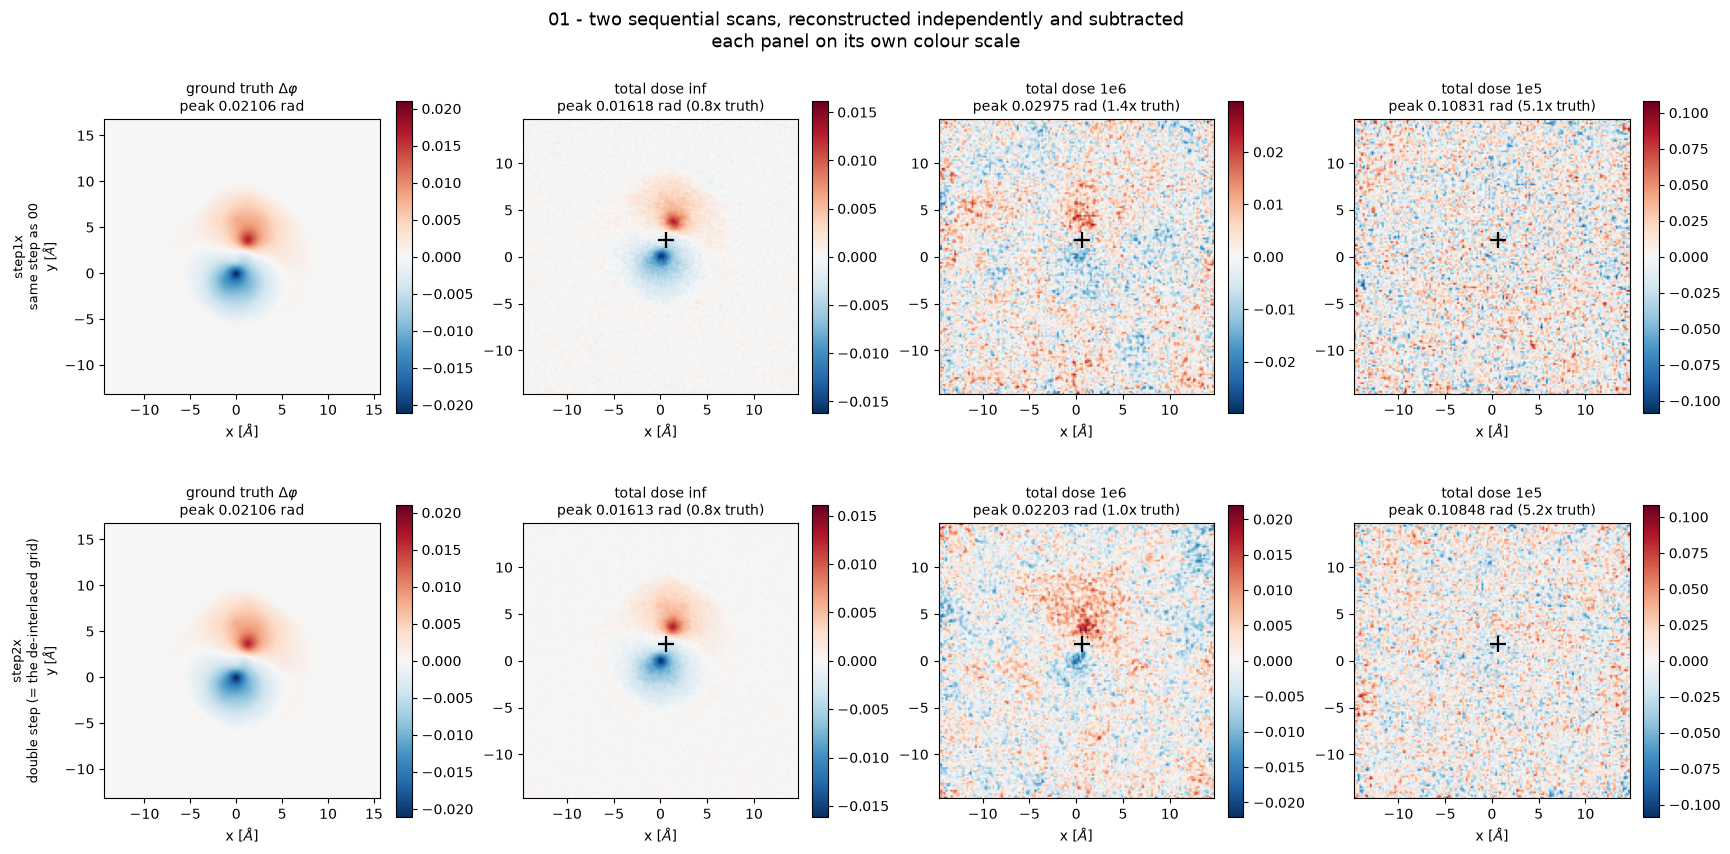

In [5]:
ncol = len(DOSE_KEYS) + 1
fig, axes = plt.subplots(len(SCAN_CONFIGS), ncol,
                         figsize=(4.3 * ncol, 4.3 * len(SCAN_CONFIGS)),
                         constrained_layout=True, squeeze=False)
tvmax = float(np.abs(delta_phi_true).max())
obj_axis = (np.arange(N_OBJECT_PX) - N_OBJECT_PX // 2) * OBJECT_DX_ANG

for row, (tag, cfg) in enumerate(SCAN_CONFIGS.items()):
    ax = axes[row][0]
    im = ax.imshow(delta_phi_true.T, extent=[obj_axis[0], obj_axis[-1]] * 2,
                   origin="lower", cmap="RdBu_r", vmin=-tvmax, vmax=tvmax)
    ax.set_xlim(blob_centre[0] - 15, blob_centre[0] + 15)
    ax.set_ylim(blob_centre[1] - 15, blob_centre[1] + 15)
    ax.set_title(r"ground truth $\Delta\varphi$" + f"\npeak {tvmax:.5f} rad", fontsize=10)
    ax.set_ylabel(f"{tag}\n{cfg['label']}\n" + r"y [$\AA$]", fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.8)

    for col, dose_key in enumerate(DOSE_KEYS, start=1):
        ax = axes[row][col]
        d = results[(tag, dose_key)]["delta_phi"]
        px = results[(tag, dose_key)]["pixel_size_ang"]
        ax_d = (np.arange(d.shape[0]) - d.shape[0] / 2 + 0.5) * px
        lim = float(np.abs(d).max())
        im = ax.imshow(d.T, extent=[ax_d[0], ax_d[-1]] * 2, origin="lower",
                       cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.plot(*blob_centre, "k+", ms=12, mew=1.6)
        ax.set_title(f"total dose {dose_key}\npeak {lim:.5f} rad "
                     f"({lim/tvmax:.1f}x truth)", fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.8)
    for ax in axes[row]:
        ax.set_xlabel(r"x [$\AA$]")

fig.suptitle("01 - two sequential scans, reconstructed independently and subtracted\n"
             "each panel on its own colour scale", fontsize=13)
plt.show()

## Reading this

Compare the recovered peak against the truth's $0.0211\ \mathrm{rad}$. The excitation is a
perturbation of order $10^{-2}$ rad on a base phase spanning $0.24\ \mathrm{rad}$, so the
difference of two independent reconstructions has to be accurate to a few percent of the
object before anything of the excitation survives in it. Nothing in the pipeline enforces
that: the two reconstructions never see each other.

`step2x` is the configuration to quote against the other methods, since it reconstructs on
the same $0.3282\ \mathrm{\AA}$ grid that de-interlacing notebook 00's cube produces.
`step1x` spends the same electrons over twice as many positions, which is the trade this
method actually faces in an experiment.

Neither dataset was written to disk - rerun this notebook to reproduce them. Only the
reconstructed phases and $\Delta\varphi$ are saved, with a readable `.json` beside each.